# Clasificación de la intención en reportes ciudadanos con BERT

## Universidad San Francisco de Quito

### Colegio de Posgrados

#### Maestría en Ciencia de Datos - Módulo: Analítica Avanzada

Los ciudadanos del Distrito Metropolitano de Quito (DMQ) envían reportes con un formulario de **Survey123**. Cada reporte queda como un punto en una capa de **ArcGIS Online**, con su categoría (`vias`, `basura`, `seguridad`…) y un texto libre (`descripcion`). La capa dice **qué** problema hay y **dónde**, pero no **qué pide** el ciudadano. Esa información solo está en el texto.

| Texto | Intención |
|---|---|
| *"Anoche asaltaron a una señora en la parada, ya van tres este mes"* | **denuncia** → control policial |
| *"¿Hay algún plan para poner más patrullajes en el barrio?"* | **consulta** → comunicación |

**Objetivo.** Ajustar BERT en español para clasificar cada reporte en una de seis intenciones (`queja`, `denuncia`, `solicitud`, `consulta`, `sugerencia`, `agradecimiento`), evaluarlo sobre la capa real de ArcGIS Online y **desplegarlo en ArcGIS** como paquete de deep learning (`.dlpk`).

**Preguntas**

1. ¿Basta un modelo de sentimiento ya entrenado, o hace falta ajustar uno para la intención?
2. ¿Cuánto mejora BERT frente a una línea base clásica (TF-IDF) y frente a un SLM generativo sin entrenar (Qwen 2.5 7B)?
3. ¿Cuánto cae el desempeño con textos escritos por personas frente a textos sintéticos?
4. ¿Qué patrones espaciales aparecen al clasificar los 1 500 reportes de la capa?

## Configuración de Entorno de Trabajo

In [1]:
import json
import os
import random
import shutil
import tempfile
import time
import zipfile
from getpass import getpass
from importlib.machinery import SourceFileLoader
from importlib.util import module_from_spec, spec_from_loader
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from datasets import load_dataset
from matplotlib.path import Path as Poligono
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline, make_union
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup, pipeline)

c:\Github\clasificador-intencion-dmq\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1015 22:05:31.275000 17588 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# Parámetros
RAIZ = Path.cwd()
DATOS = RAIZ / "datos"
SALIDAS = RAIZ / "salidas"
SALIDAS.mkdir(exist_ok=True)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Modelos 
MODEL_NAME = os.getenv("MODEL_NAME", "dccuchile/bert-base-spanish-wwm-uncased")                  # BETO
MODELO_SENTIMIENTO = os.getenv("MODELO_SENTIMIENTO", "pysentimiento/robertuito-sentiment-analysis")

# Entrenamiento
MAX_LENGTH = 128
BATCH_SIZE = 16
LR = 2e-5
N_EPOCHS = 4          

# Intenciones
INTENCIONES = ["queja", "denuncia", "solicitud", "consulta", "sugerencia", "agradecimiento"]
id2label = dict(enumerate(INTENCIONES))
label2id = {v: k for k, v in id2label.items()}

# ArcGIS Online
PORTAL = os.getenv("ARCGIS_PORTAL", "https://www.arcgis.com")
URL_REPORTES = os.getenv("URL_REPORTES", "https://services2.arcgis.com/kHvSRXWQHCjXtMkT/arcgis/rest/services/"
                                         "service_ef0c0ccbb59144dcb9c607ef4f11c8ec/FeatureServer/0")
URL_PARROQUIAS = os.getenv("URL_PARROQUIAS", "https://services1.arcgis.com/UOl0yzPDLol8nS3m/arcgis/rest/services/"
                                             "Parroquias_DMQ/FeatureServer/2")
CAMPO_PARROQUIA = "dpa_despar"
ESCRIBIR_EN_ARCGIS = True     # True: agrega intencion_bert y confianza_bert a la capa (sección 11.4)

# SLM local para la comparación (Ollama)
OLLAMA_URL = os.getenv("OLLAMA_URL", "http://localhost:11434")
MODELO_SLM = "qwen2.5:7b"
N_SLM = 120           # textos sintéticos que clasifica el SLM (además de la prueba humana)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
COLORES = dict(zip(INTENCIONES, ["#d1495b", "#8e3b9e", "#2e86ab", "#f4a259", "#5b8e7d", "#4caf50"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Dispositivo: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

Dispositivo: cuda (NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU)


## 1. Punto de partida: ¿basta un modelo de sentimiento?

Como en clase, primero se prueba un modelo ya entrenado con `pipeline`: **RoBERTuito** clasifica sentimiento (NEG / NEU / POS). La pregunta es si el sentimiento alcanza para saber qué pide el ciudadano.

In [3]:
clf_sentimiento = pipeline(
    "text-classification",
    model=MODELO_SENTIMIENTO,
    tokenizer=MODELO_SENTIMIENTO,
    top_k=None,
    device=DEVICE,
)

ejemplos = {
    "queja": "Otra vez sin luz toda la cuadra, esto ya es costumbre y uno pagando impuestos",
    "denuncia": "Están botando escombros en la quebrada por las noches, camionetas sin placa",
    "solicitud": "Necesito que vengan a podar el árbol que está topando los cables de luz",
    "consulta": "¿Hasta qué fecha va el corte de agua programado en Conocoto?",
    "sugerencia": "Deberían poner bicicleteros en la parada de la Ecovía",
    "agradecimiento": "Gracias por arreglar el alumbrado tan rápido",
}
for (intencion, texto), puntajes in zip(ejemplos.items(), clf_sentimiento(list(ejemplos.values()))):
    mejor = max(puntajes, key=lambda r: r["score"])
    print(f"{intencion:<15} → {mejor['label']} ({mejor['score']:.2f})   {texto}")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 468.77it/s]


queja           → NEG (0.97)   Otra vez sin luz toda la cuadra, esto ya es costumbre y uno pagando impuestos
denuncia        → NEG (0.88)   Están botando escombros en la quebrada por las noches, camionetas sin placa
solicitud       → NEG (0.52)   Necesito que vengan a podar el árbol que está topando los cables de luz
consulta        → NEU (0.71)   ¿Hasta qué fecha va el corte de agua programado en Conocoto?
sugerencia      → NEU (0.53)   Deberían poner bicicleteros en la parada de la Ecovía
agradecimiento  → POS (0.69)   Gracias por arreglar el alumbrado tan rápido


Queja, denuncia y, a menudo, solicitud salen igual de **negativas**: el sentimiento mide el **tono**, no la **intención**. Para el Municipio, una queja y una denuncia llevan a acciones distintas, así que hace falta un clasificador propio.

## 2. Datos de ArcGIS Online: la capa de reportes

Los reportes se leen directamente de la capa del formulario Survey123 con la **API REST de ArcGIS** (`generateToken` + `query`). La capa es privada, así que se pide un token con tu usuario de ArcGIS Online. Si no hay credenciales, se usa la copia local `datos/reportes_dmq.csv`.

Los reportes son **simulados con patrones conocidos**. Su intención real está en `datos/verdad_reportes.csv`, que **no** se subió a la capa. En un caso real esa columna no existiría; aquí permite medir cuánto acierta el modelo sobre la capa.

In [4]:
def cargar_env(ruta: Path) -> None:
    # Carga variables
    if not ruta.exists():
        return
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        if "=" in linea and not linea.lstrip().startswith("#"):
            clave, valor = linea.split("=", 1)
            os.environ.setdefault(clave.strip(), valor.strip().strip('"').strip("'"))


def token_arcgis(usuario: str, clave: str) -> str:
    # Token de ArcGIS Online
    r = requests.post(f"{PORTAL}/sharing/rest/generateToken", timeout=30, data={
        "username": usuario, "password": clave, "referer": PORTAL, "expiration": 120, "f": "json"})
    r.raise_for_status()
    respuesta = r.json()
    if "token" not in respuesta:
        raise RuntimeError(f"ArcGIS no entregó token: {respuesta.get('error')}")
    return respuesta["token"]


def consultar_capa(url: str, token: str | None = None, campos: str = "*", lote: int = 1000) -> list[dict]:
    # Descarga todos los registros de una capa como GeoJSON (WGS84)
    features, desde = [], 0
    while True:
        params = {"where": "1=1", "outFields": campos, "outSR": 4326, "f": "geojson",
                  "resultOffset": desde, "resultRecordCount": lote}
        if token:
            params["token"] = token
        r = requests.get(f"{url}/query", params=params, timeout=60)
        r.raise_for_status()
        pagina = r.json()
        if "error" in pagina:
            raise RuntimeError(pagina["error"])
        features += pagina["features"]
        if len(pagina["features"]) < lote:
            return features
        desde += lote


def a_dataframe(features: list[dict]) -> pd.DataFrame:
    # Atributos + coordenadas de una capa de puntos
    return pd.DataFrame([{**f["properties"], "lon": f["geometry"]["coordinates"][0],
                          "lat": f["geometry"]["coordinates"][1]} for f in features])

In [5]:
cargar_env(RAIZ / ".env")
usuario = os.getenv("ARCGIS_USERNAME")
TOKEN = None

if usuario:
    TOKEN = token_arcgis(usuario, os.getenv("ARCGIS_PASSWORD") or getpass(f"Contraseña de {usuario}: "))
    reportes = a_dataframe(consultar_capa(URL_REPORTES, TOKEN))
    print(f"ArcGIS Online: {len(reportes)} reportes leídos de la capa")
else:
    reportes = pd.read_csv(DATOS / "reportes_dmq.csv")
    print(f"Sin credenciales de ArcGIS: {len(reportes)} reportes leídos de datos/reportes_dmq.csv")

verdad = pd.read_csv(DATOS / "verdad_reportes.csv")
reportes = reportes.merge(verdad[["codigo", "intencion", "parroquia"]], on="codigo", how="left")
print(f"Con intención real conocida: {reportes['intencion'].notna().sum()} de {len(reportes)}")
reportes[["codigo", "categoria", "gravedad", "estado", "descripcion"]].head()

ArcGIS Online: 1500 reportes leídos de la capa
Con intención real conocida: 1500 de 1500


,codigo,categoria,gravedad,estado,descripcion
0,R-00001,basura,media,recibido,"Hola, los vecinos estamos molestos porque la b..."
1,R-00002,alcantarillado,media,en_proceso,"Buenas tardes. Excelente trabajo, gracias por ..."
2,R-00003,basura,media,resuelto,Pido al Municipio recoger la basura acumulada ...
3,R-00004,animales,baja,resuelto,Estimados: sugiero esterilizar a los perros ca...
4,R-00005,animales,baja,en_proceso,Buenos días. Abandonan cachorros en el parque ...


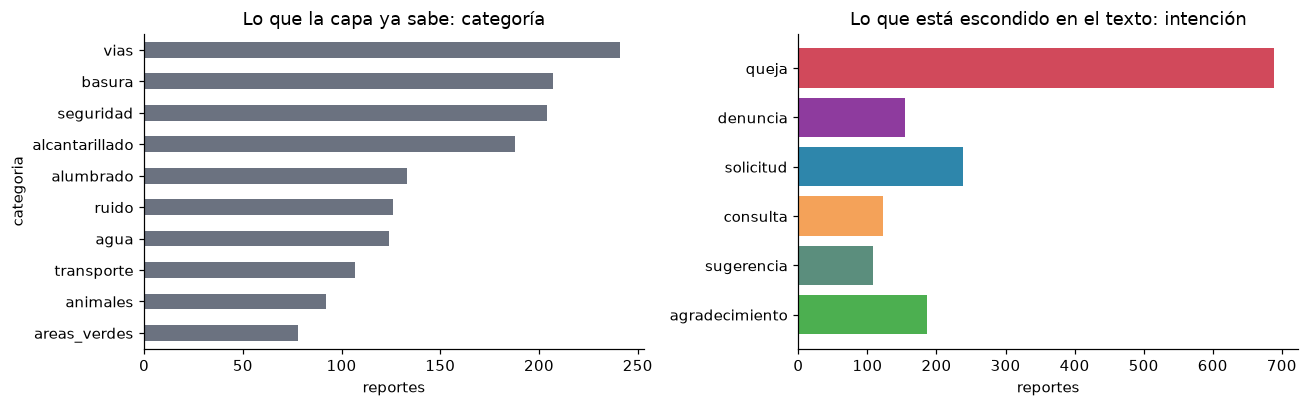

intencion,queja,denuncia,solicitud,consulta,sugerencia,agradecimiento
categoria,,,,,,
agua,74,0,21,9,9,11
alcantarillado,119,0,27,12,14,16
alumbrado,80,0,19,9,8,17
animales,26,23,15,5,9,14
areas_verdes,29,0,12,11,5,21
basura,84,30,36,18,14,25
ruido,33,17,25,14,10,27
seguridad,52,85,20,17,13,17
transporte,53,0,25,9,5,15


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
reportes["categoria"].value_counts().sort_values().plot.barh(ax=ax[0], color="#6b7280")
ax[0].set_title("Lo que la capa ya sabe: categoría")
conteo = reportes["intencion"].value_counts().reindex(INTENCIONES)
ax[1].barh(conteo.index[::-1], conteo.values[::-1], color=[COLORES[i] for i in conteo.index[::-1]])
ax[1].set_title("Lo que está escondido en el texto: intención")
for a in ax:
    a.set_xlabel("reportes")
plt.tight_layout()
plt.show()

# La categoría sola no determina la intención
pd.crosstab(reportes["categoria"], reportes["intencion"])[INTENCIONES]

## 3. Dataset de entrenamiento

Hay tres conjuntos:

| Archivo | Descripción | 
|---|---|
| `entrenamiento.csv` | Textos sintéticos con 16 estructuras de frase | 
| `prueba_sintetica.csv` | Textos sintéticos con **6 estructuras que el modelo nunca ve** (`Q5, D4, S4, C3, G3, A3`) | 
| `prueba_humana.csv` | 36 reportes **escritos a mano**, sin plantillas | 

Si se partiera al azar, la misma frase plantilla quedaría en entrenamiento y prueba, y el modelo aprobaría memorizando. Por eso la prueba sintética usa estructuras reservadas. Los textos se generan con `generador/generar_datos.py`.

In [7]:
raw = load_dataset("csv", data_files={
    "entrenamiento": str(DATOS / "entrenamiento.csv"),
    "prueba_sintetica": str(DATOS / "prueba_sintetica.csv"),
    "prueba_humana": str(DATOS / "prueba_humana.csv"),
})

# Fuera del entrenamiento cualquier texto idéntico a uno de la capa
textos_capa = set(reportes["descripcion"])
entrenamiento = raw["entrenamiento"].filter(lambda f: f["texto"] not in textos_capa)
print(raw)
print(f"Quitados por coincidir con la capa: {len(raw['entrenamiento']) - len(entrenamiento)}")

DatasetDict({
    entrenamiento: Dataset({
        features: ['texto', 'intencion', 'categoria', 'plantilla'],
        num_rows: 1788
    })
    prueba_sintetica: Dataset({
        features: ['texto', 'intencion', 'categoria', 'plantilla'],
        num_rows: 593
    })
    prueba_humana: Dataset({
        features: ['texto', 'intencion', 'categoria', 'plantilla'],
        num_rows: 36
    })
})
Quitados por coincidir con la capa: 9


In [8]:
# División entrenamiento / validación
idx = list(range(len(entrenamiento)))
random.seed(SEED)
random.shuffle(idx)

n_val = int(0.2 * len(idx))
val_idx, train_idx = idx[:n_val], idx[n_val:]

train_texts = [entrenamiento[i]["texto"] for i in train_idx]
train_labels = [label2id[entrenamiento[i]["intencion"]] for i in train_idx]
val_texts = [entrenamiento[i]["texto"] for i in val_idx]
val_labels = [label2id[entrenamiento[i]["intencion"]] for i in val_idx]

prueba = {
    nombre: (list(raw[split]["texto"]), [label2id[e] for e in raw[split]["intencion"]])
    for nombre, split in [("prueba sintética", "prueba_sintetica"), ("prueba humana", "prueba_humana")]
}
print(f"train {len(train_texts)} · val {len(val_texts)} · "
      f"prueba sintética {len(prueba['prueba sintética'][0])} · prueba humana {len(prueba['prueba humana'][0])}")
for texto, label in zip(train_texts[:4], train_labels[:4]):
    print(f"  [{id2label[label]}] {texto}")

train 1424 · val 355 · prueba sintética 593 · prueba humana 36
  [solicitud] Como vecino del sector: por favor, necesitamos revisar el alumbrado por el redondel.
  [queja] Buenos días. Estoy cansado, el colector está roto junto al mercado desde el lunes. Es indignante.
  [queja] Buenos días. Estoy cansado, un perro atropellado sigue en la calle frente a la escuela otra vez esta semana.
  [consulta] Quisiera saber si está previsto reparar la vereda en la entrada del conjunto.


## 4. Modelo: BERT con una capa de clasificación de 6 salidas

Se usa el mismo BERT en español de clase. `AutoModelForSequenceClassification` agrega una capa lineal nueva (los pesos `classifier.*` que el reporte de carga marca como *MISSING*) que se entrena junto con el resto.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(INTENCIONES),
    id2label=id2label,
    label2id=label2id,
).to(DEVICE)

print(tokenizer.tokenize("Ya no aguanto más, el hueco de la Maldonado se traga las llantas"))
print(f"Parámetros: {sum(p.numel() for p in model.parameters()) / 1e6:.0f} M")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 20583.36it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe

['ya', 'no', 'aguanto', 'más', ',', 'el', 'hueco', 'de', 'la', 'maldonado', 'se', 'tra', '##ga', 'las', 'llan', '##tas']
Parámetros: 110 M


## 5. Dataset y DataLoader

In [10]:
class ReporteDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.long)
        return item


def tokenizar(tokenizer, texts, max_length=MAX_LENGTH):
    return tokenizer(list(texts), truncation=True, padding=True, max_length=max_length, return_tensors=None)


def cargador(texts, labels, shuffle=False):
    return DataLoader(ReporteDataset(tokenizar(tokenizer, texts), labels), batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = cargador(train_texts, train_labels, shuffle=True)   # se baraja en cada época
val_loader = cargador(val_texts, val_labels)

## 6. Entrenamiento

`AdamW` + *warmup* lineal del 10 % + recorte de gradiente. 

Dos cambios: los datos se **barajan** en cada época y, al final de cada una, se mide el F1 en validación para **conservar la mejor época** (con datos de plantillas, entrenar de más memoriza).

In [11]:
@torch.no_grad()
def evaluar(model, loader, device):
    model.eval()
    y_true, y_pred = [], []
    for batch in loader:
        labels = batch.pop("labels")
        batch = {k: v.to(device) for k, v in batch.items()}
        y_pred.extend(model(**batch).logits.argmax(dim=-1).cpu().tolist())
        y_true.extend(labels.tolist())
    return (
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average="macro"),
        y_true,
        y_pred,
    )


def entrenar_epoca(model, loader, optimizer, scheduler, device):
    model.train()
    perdidas = []
    for batch in loader:
        labels = batch.pop("labels").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad()
        loss = model(**batch, labels=labels).loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1)
        optimizer.step()
        scheduler.step()
        perdidas.append(loss.item())
    return float(np.mean(perdidas))

In [12]:
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * N_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

historial, mejor_f1, mejor_estado = [], -1.0, None
inicio = time.time()
for epoch in range(1, N_EPOCHS + 1):
    perdida = entrenar_epoca(model, train_loader, optimizer, scheduler, DEVICE)
    acc, f1, _, _ = evaluar(model, val_loader, DEVICE)
    historial.append({"epoch": epoch, "loss": perdida, "val_accuracy": acc, "val_f1": f1})
    print(f"Época {epoch}: loss {perdida:.4f} · val accuracy {acc:.3f} · val F1 {f1:.3f}")
    if f1 > mejor_f1:
        mejor_f1 = f1
        mejor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(mejor_estado)
mejor_epoca = max(historial, key=lambda h: h["val_f1"])["epoch"]
print(f"\nEntrenamiento: {(time.time() - inicio) / 60:.1f} min en {DEVICE} · mejor época: {mejor_epoca}")

Época 1: loss 0.7968 · val accuracy 1.000 · val F1 1.000
Época 2: loss 0.0091 · val accuracy 1.000 · val F1 1.000
Época 3: loss 0.0051 · val accuracy 1.000 · val F1 1.000
Época 4: loss 0.0042 · val accuracy 1.000 · val F1 1.000

Entrenamiento: 0.9 min en cuda · mejor época: 1


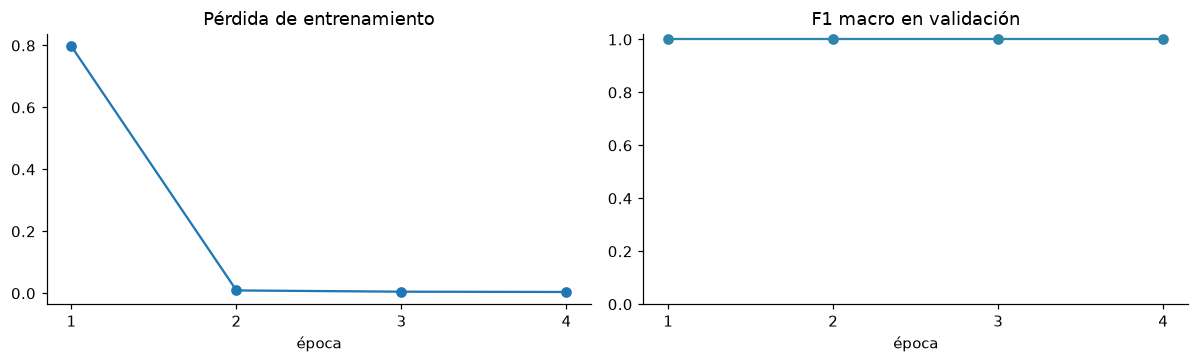

In [13]:
h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(h["epoch"], h["loss"], "o-")
ax[0].set_title("Pérdida de entrenamiento")
ax[1].plot(h["epoch"], h["val_f1"], "o-", color="#2e86ab")
ax[1].set_ylim(0, 1.02)
ax[1].set_title("F1 macro en validación")
for a in ax:
    a.set_xlabel("época")
    a.set_xticks(h["epoch"])
plt.tight_layout()
plt.show()

## 7. Evaluación

Validación, prueba sintética (estructuras nuevas) y prueba humana (textos reales).

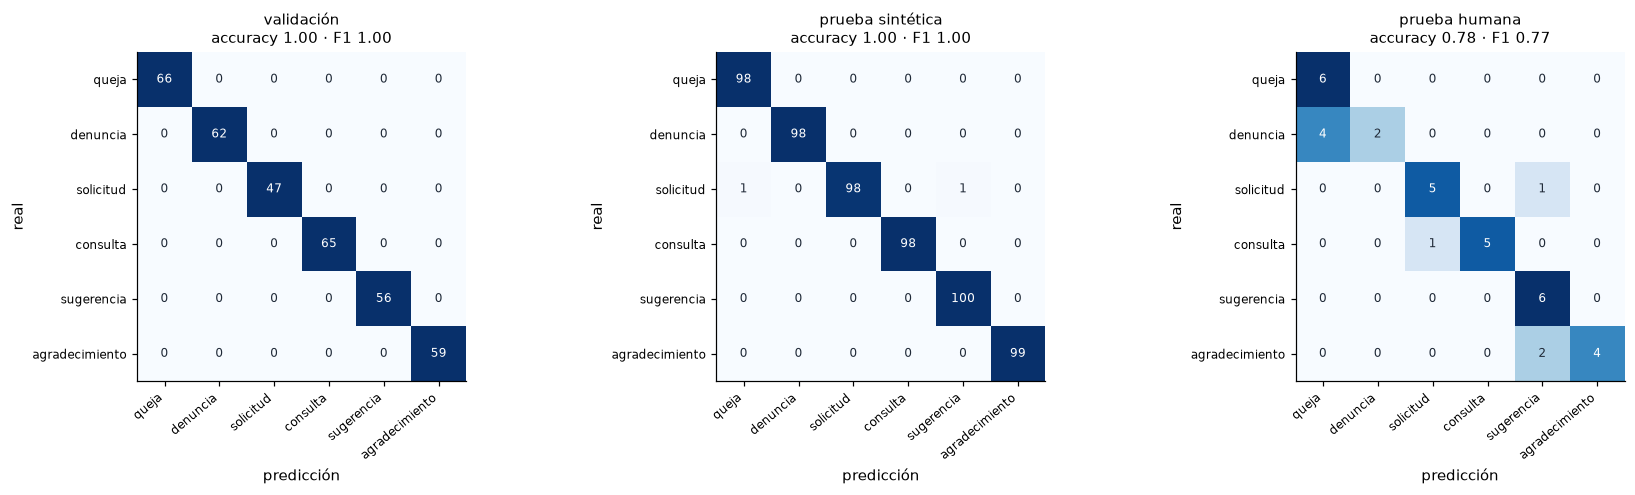

Prueba humana · Accuracy: 77.78% · F1-Score: 76.54%

                precision    recall  f1-score   support

         queja       0.60      1.00      0.75         6
      denuncia       1.00      0.33      0.50         6
     solicitud       0.83      0.83      0.83         6
      consulta       1.00      0.83      0.91         6
    sugerencia       0.67      1.00      0.80         6
agradecimiento       1.00      0.67      0.80         6

      accuracy                           0.78        36
     macro avg       0.85      0.78      0.77        36
  weighted avg       0.85      0.78      0.77        36



In [14]:
def matriz_confusion(y_true, y_pred, titulo, ax):
    m = confusion_matrix(y_true, y_pred, labels=range(len(INTENCIONES)))
    norm = m / np.maximum(m.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(INTENCIONES)), INTENCIONES, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(INTENCIONES)), INTENCIONES, fontsize=8)
    for r in range(len(INTENCIONES)):
        for c in range(len(INTENCIONES)):
            ax.text(c, r, m[r, c], ha="center", va="center", fontsize=8,
                    color="white" if norm[r, c] > 0.6 else "#1f2937")
    ax.set_xlabel("predicción")
    ax.set_ylabel("real")
    ax.set_title(titulo, fontsize=10)


conjuntos = {"validación": (val_texts, val_labels), **prueba}
resultados_bert = {}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for k, (nombre, (texts, labels)) in enumerate(conjuntos.items()):
    acc, f1, y_true, y_pred = evaluar(model, cargador(texts, labels), DEVICE)
    resultados_bert[nombre] = (acc, f1, y_pred)
    matriz_confusion(y_true, y_pred, f"{nombre}\naccuracy {acc:.2f} · F1 {f1:.2f}", ax[k])
plt.tight_layout()
plt.show()

acc, f1, y_pred = resultados_bert["prueba humana"]
print(f"Prueba humana · Accuracy: {acc * 100:.2f}% · F1-Score: {f1 * 100:.2f}%\n")
print(classification_report(prueba["prueba humana"][1], y_pred, labels=range(len(INTENCIONES)),
                            target_names=INTENCIONES, digits=2, zero_division=0))

## 8. Predicción

In [15]:
@torch.no_grad()
def predecir(textos, tokenizer, model, device, max_length=MAX_LENGTH, batch_size=64):
    model.eval()
    resultados = []
    for i in range(0, len(textos), batch_size):
        lote = list(textos[i:i + batch_size])
        enc = tokenizer(lote, truncation=True, padding=True, max_length=max_length, return_tensors="pt")
        enc = {k: v.to(device) for k, v in enc.items()}
        probs = torch.softmax(model(**enc).logits, dim=-1).cpu()
        for texto, p in zip(lote, probs):
            j = int(p.argmax())
            resultados.append({"texto": texto, "label": id2label[j], "confianza": float(p[j]),
                               **{f"p_{e}": float(p[k]) for k, e in id2label.items()}})
    return resultados

In [16]:
textos = [
    "Ya no aguanto más, el hueco de la Av. Maldonado se traga las llantas y nadie aparece",
    "Hay unos tipos vendiendo droga afuera del colegio todas las tardes",
    "Por favor manden a recoger la basura acumulada en la esquina del mercado",
    "¿El recolector pasa los martes o los miércoles por La Floresta?",
    "Estaría chévere que pongan puntos de reciclaje en cada barrio",
    "Mil gracias a los señores que vinieron a tapar el hueco, quedó perfecto",
    "Gracias de antemano, necesitamos que poden el árbol que tapa el poste",
    "No hay agua desde ayer y ni avisaron nada",
]
for r in predecir(textos, tokenizer, model, DEVICE):
    print(f"[{r['label'].upper()}] confianza {r['confianza']:.2f}")
    print(f"    {r['texto']}")

[QUEJA] confianza 0.98
    Ya no aguanto más, el hueco de la Av. Maldonado se traga las llantas y nadie aparece
[QUEJA] confianza 0.91
    Hay unos tipos vendiendo droga afuera del colegio todas las tardes
[SOLICITUD] confianza 0.99
    Por favor manden a recoger la basura acumulada en la esquina del mercado
[CONSULTA] confianza 0.43
    ¿El recolector pasa los martes o los miércoles por La Floresta?
[SUGERENCIA] confianza 0.91
    Estaría chévere que pongan puntos de reciclaje en cada barrio
[AGRADECIMIENTO] confianza 0.83
    Mil gracias a los señores que vinieron a tapar el hueco, quedó perfecto
[SOLICITUD] confianza 0.96
    Gracias de antemano, necesitamos que poden el árbol que tapa el poste
[QUEJA] confianza 0.98
    No hay agua desde ayer y ni avisaron nada


## 9. Comparación: TF-IDF y un SLM generativo sin entrenar

- **TF-IDF + regresión logística**: línea base clásica
- **Qwen 2.5 7B (Ollama), *zero-shot***: el SLM de la tesis, con una instrucción y la definición de cada intención, sin entrenamiento. La salida se restringe con un esquema JSON para que siempre sea una de las seis etiquetas.

Se mide también el **tiempo por texto**: el costo de clasificar toda la capa.

In [17]:
comparacion = []


def registrar(modelo, conjunto, y_true, y_pred, segundos):
    comparacion.append({"modelo": modelo, "conjunto": conjunto, "n": len(y_true),
                        "accuracy": accuracy_score(y_true, y_pred),
                        "f1_macro": f1_score(y_true, y_pred, labels=range(len(INTENCIONES)), average="macro"),
                        "ms_por_texto": 1000 * segundos / len(y_true)})


# BETO (tiempo de inferencia medido aparte del de evaluación)
for nombre, (texts, labels) in prueba.items():
    t0 = time.time()
    pred = [label2id[r["label"]] for r in predecir(texts, tokenizer, model, DEVICE)]
    registrar("BETO ajustado", nombre, labels, pred, time.time() - t0)

# Línea base TF-IDF (n-gramas de palabras y de caracteres)
tfidf = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
    LogisticRegression(max_iter=2000, C=4.0),
)
tfidf.fit(train_texts, train_labels)
for nombre, (texts, labels) in prueba.items():
    t0 = time.time()
    pred = tfidf.predict(list(texts))
    registrar("TF-IDF + LogReg", nombre, labels, pred, time.time() - t0)

In [18]:
PROMPT_SLM = '''Clasifica la intención de este reporte ciudadano enviado al Municipio de Quito.

- queja: expresa molestia o reclamo por un problema o por la mala atención.
- denuncia: informa una conducta indebida o ilegal de terceros (delitos, botar basura, ruido, maltrato animal) para que la autoridad actúe.
- solicitud: pide una acción, servicio o reparación concreta.
- consulta: pide información.
- sugerencia: propone una idea o mejora.
- agradecimiento: agradece o felicita por algo que se hizo.

Reporte: «{texto}»'''

ESQUEMA_SLM = {"type": "object", "required": ["intencion"],
               "properties": {"intencion": {"type": "string", "enum": INTENCIONES}}}


def ollama_disponible() -> bool:
    try:
        modelos = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3).json()["models"]
        return any(m["name"].split(":latest")[0] == MODELO_SLM for m in modelos)
    except requests.RequestException:
        return False


def clasificar_slm(texto: str) -> str:
    r = requests.post(f"{OLLAMA_URL}/api/chat", timeout=120, json={
        "model": MODELO_SLM, "stream": False, "format": ESQUEMA_SLM,
        "options": {"temperature": 0, "num_ctx": 2048},
        "messages": [{"role": "user", "content": PROMPT_SLM.format(texto=texto)}]})
    r.raise_for_status()
    return json.loads(r.json()["message"]["content"])["intencion"]


if ollama_disponible():
    clasificar_slm("calentamiento")                        # carga el modelo antes de medir tiempos
    rng = random.Random(SEED)
    textos_sint, labels_sint = prueba["prueba sintética"]
    muestra = rng.sample(range(len(textos_sint)), min(N_SLM, len(textos_sint)))
    conjuntos_slm = {"prueba sintética": ([textos_sint[i] for i in muestra], [labels_sint[i] for i in muestra]),
                     "prueba humana": prueba["prueba humana"]}
    for nombre, (texts, labels) in conjuntos_slm.items():
        t0 = time.time()
        pred = [label2id[clasificar_slm(t)] for t in texts]
        registrar(f"{MODELO_SLM} zero-shot", nombre, labels, pred, time.time() - t0)
        print(f"{MODELO_SLM} · {nombre}: listo ({len(texts)} textos)")
else:
    print(f"Ollama no responde en {OLLAMA_URL} o falta '{MODELO_SLM}': se omite (ollama pull {MODELO_SLM}).")

qwen2.5:7b · prueba sintética: listo (120 textos)
qwen2.5:7b · prueba humana: listo (36 textos)


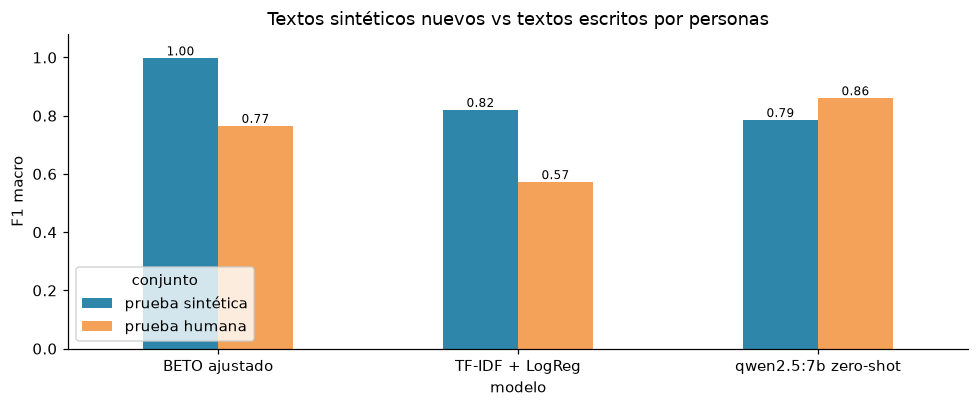

,modelo,conjunto,n,accuracy,f1_macro,ms_por_texto,seg_para_1500
0,BETO ajustado,prueba sintética,593,0.997,0.997,2.6,3.9
1,BETO ajustado,prueba humana,36,0.778,0.765,1.9,2.8
2,TF-IDF + LogReg,prueba sintética,593,0.826,0.820,0.2,0.3
3,TF-IDF + LogReg,prueba humana,36,0.583,0.572,0.2,0.3
4,qwen2.5:7b zero-shot,prueba sintética,120,0.817,0.785,1070.8,1606.2
5,qwen2.5:7b zero-shot,prueba humana,36,0.861,0.860,1134.7,1702.0


In [19]:
tabla = pd.DataFrame(comparacion).round({"accuracy": 3, "f1_macro": 3, "ms_por_texto": 1})
tabla["seg_para_1500"] = (tabla["ms_por_texto"] * 1.5).round(1)
tabla.to_csv(SALIDAS / "comparacion_modelos.csv", index=False)

f1_por_conjunto = tabla.pivot(index="modelo", columns="conjunto", values="f1_macro")[["prueba sintética", "prueba humana"]]
ax = f1_por_conjunto.plot.bar(figsize=(9, 3.8), rot=0, color=["#2e86ab", "#f4a259"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1 macro")
ax.set_title("Textos sintéticos nuevos vs textos escritos por personas")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()
tabla

## 10. Aplicación a la capa de ArcGIS

BERT clasifica el campo `descripcion` de los 1 500 reportes. Luego cada punto se asigna a su parroquia con una **unión espacial** (punto en polígono) contra la capa de parroquias del DMQ: la capa de reportes no tiene parroquia a propósito.

1500 reportes clasificados en 5.4 s
Accuracy sobre la capa: 1.000 · F1 macro: 1.000


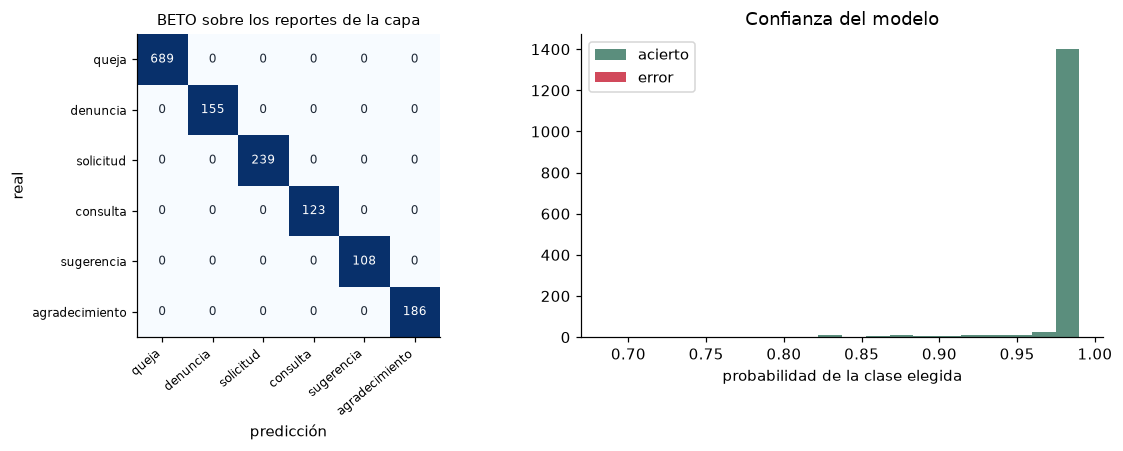

In [20]:
inicio = time.time()
pred = predecir(reportes["descripcion"].astype(str).tolist(), tokenizer, model, DEVICE)
reportes["intencion_bert"] = [r["label"] for r in pred]
reportes["confianza_bert"] = [round(r["confianza"], 3) for r in pred]
print(f"{len(reportes)} reportes clasificados en {time.time() - inicio:.1f} s")

evaluables = reportes.dropna(subset=["intencion"])
y_true = evaluables["intencion"].map(label2id)
y_pred = evaluables["intencion_bert"].map(label2id)
print(f"Accuracy sobre la capa: {accuracy_score(y_true, y_pred):.3f} · "
      f"F1 macro: {f1_score(y_true, y_pred, average='macro'):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
matriz_confusion(y_true, y_pred, "BETO sobre los reportes de la capa", ax[0])
acierto = evaluables["intencion"] == evaluables["intencion_bert"]
ax[1].hist([evaluables.loc[acierto, "confianza_bert"], evaluables.loc[~acierto, "confianza_bert"]],
           bins=20, stacked=True, color=["#5b8e7d", "#d1495b"], label=["acierto", "error"])
ax[1].set_title("Confianza del modelo")
ax[1].set_xlabel("probabilidad de la clase elegida")
ax[1].legend()
plt.tight_layout()
plt.show()

In [21]:
def union_espacial(lon, lat, poligonos: list[dict], campo: str) -> np.ndarray:
    # Asigna a cada punto el valor `campo` del polígono que lo contiene (respeta huecos)
    puntos = np.column_stack([lon, lat])
    asignado = np.full(len(puntos), None, dtype=object)
    for f in poligonos:
        geom = f["geometry"]
        partes = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
        dentro = np.zeros(len(puntos), dtype=bool)
        for anillos in partes:
            en_parte = Poligono(anillos[0]).contains_points(puntos)
            for hueco in anillos[1:]:
                en_parte &= ~Poligono(hueco).contains_points(puntos)
            dentro |= en_parte
        asignado[dentro] = f["properties"][campo]
    return asignado


parroquias = consultar_capa(URL_PARROQUIAS, campos=CAMPO_PARROQUIA)    # capa pública
reportes["parroquia_espacial"] = union_espacial(reportes["lon"], reportes["lat"], parroquias, CAMPO_PARROQUIA)
coinciden = (reportes["parroquia_espacial"] == reportes["parroquia"]).mean()
print(f"{len(parroquias)} parroquias · reportes sin parroquia: {reportes['parroquia_espacial'].isna().sum()} · "
      f"coincidencia con la parroquia de origen: {coinciden:.1%}")

65 parroquias · reportes sin parroquia: 0 · coincidencia con la parroquia de origen: 100.0%


In [22]:
por_parroquia = pd.crosstab(reportes["parroquia_espacial"], reportes["intencion_bert"]).reindex(
    columns=INTENCIONES, fill_value=0)
por_parroquia["total"] = por_parroquia.sum(axis=1)
porcentaje = por_parroquia[INTENCIONES].div(por_parroquia["total"], axis=0)

pd.DataFrame({
    "más reportes": por_parroquia["total"].nlargest(5).index,
    "más denuncias": por_parroquia["denuncia"].nlargest(5).index,
    "más quejas": por_parroquia["queja"].nlargest(5).index,
    "más consultas": por_parroquia["consulta"].nlargest(5).index,
    "más agradecimientos": por_parroquia["agradecimiento"].nlargest(5).index,
}, index=range(1, 6))

,más reportes,más denuncias,más quejas,más consultas,más agradecimientos
1,CHIMBACALLE,LA CONCEPCIÓN,CHIMBACALLE,CARCELÉN,BELISARIO QUEVEDO
2,QUITUMBE,TURUBAMBA,QUITUMBE,QUITUMBE,CHIMBACALLE
3,TURUBAMBA,QUITUMBE,LA LIBERTAD,COMITÉ DEL PUEBLO,PONCEANO
4,PONCEANO,CENTRO HISTÓRICO,PONCEANO,CHIMBACALLE,LA FERROVIARIA
5,LA CONCEPCIÓN,GUANGOPOLO,SAN JUAN,ITCHIMBIA,LLANO CHICO


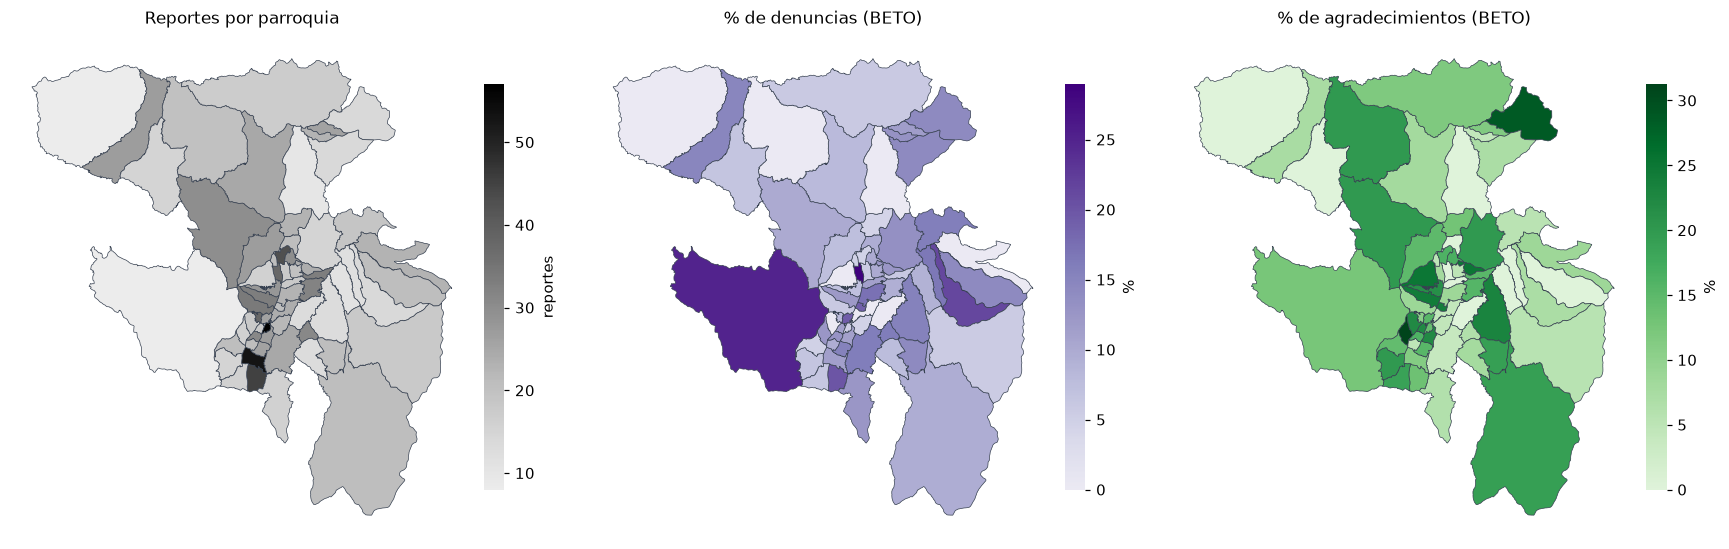

In [24]:
import matplotlib.colors as mcolors


def mapa(ax, valores: pd.Series, titulo: str, cmap: str, etiqueta: str) -> None:
    escala = mcolors.ListedColormap(plt.get_cmap(cmap)(np.linspace(0.15, 1, 256)))
    norm = plt.Normalize(valores.min(), valores.max())
    for f in parroquias:
        nombre = f["properties"][CAMPO_PARROQUIA]
        sin_datos = nombre not in valores.index or pd.isna(valores[nombre])
        geom = f["geometry"]
        for anillos in ([geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]):
            exterior = np.array(anillos[0])
            ax.fill(exterior[:, 0], exterior[:, 1], facecolor="#e5e7eb" if sin_datos else escala(norm(valores[nombre])),
                    edgecolor="#374151", linewidth=0.45, hatch="///" if sin_datos else None)
    ax.set_title(titulo, fontsize=11, pad=8)
    ax.set_aspect("equal")
    ax.axis("off")
    barra = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=escala), ax=ax, shrink=0.55, pad=0.02)
    barra.set_label(etiqueta)
    barra.outline.set_visible(False)


fig, ax = plt.subplots(1, 3, figsize=(16, 7))
mapa(ax[0], por_parroquia["total"], "Reportes por parroquia", "Greys", "reportes")
mapa(ax[1], 100 * porcentaje["denuncia"], "% de denuncias (BETO)", "Purples", "%")
mapa(ax[2], 100 * porcentaje["agradecimiento"], "% de agradecimientos (BETO)", "Greens", "%")
plt.tight_layout()
plt.savefig(SALIDAS / "mapa_intenciones.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 11. Despliegue en ArcGIS

El modelo se empaqueta como **paquete de deep learning (`.dlpk`)**, el formato que usa ArcGIS para modelos de IA. 

Desde ArcGIS Pro 3.4 un `.dlpk` puede traer un **modelo de lenguaje propio**: una carpeta con

- un archivo de definición `.emd` (JSON) que indica el tipo de modelo (`TextClassifier`) y el archivo con la función de inferencia;
- una clase Python con los métodos `__init__`, `initialize`, `getParameterInfo`, `getConfiguration` y `predict`, que recibe y devuelve un `FeatureSet` (`arcgis_dlpk/ClasificadorIntencionDMQ.py`);
- los pesos del modelo (`modelo/`, guardado con `save_pretrained`).

Ese paquete se usa en ArcGIS Pro con la herramienta **Classify Text Using Deep Learning** (caja de herramientas GeoAI) y en Python con `arcgis.learn.text.TextClassifier.from_model`. Las fuentes oficiales están en el README.

### 11.1 Empaquetar

In [25]:
NOMBRE_DLPK = "ClasificadorIntencionDMQ"     # carpeta, .emd, .py y clase deben llamarse igual

carpeta = SALIDAS / NOMBRE_DLPK
shutil.rmtree(carpeta, ignore_errors=True)
carpeta.mkdir(parents=True)

model.save_pretrained(carpeta / "modelo")
tokenizer.save_pretrained(carpeta / "modelo")
shutil.copy(RAIZ / "arcgis_dlpk" / f"{NOMBRE_DLPK}.py", carpeta)

emd = {
    "InferenceFunction": f"{NOMBRE_DLPK}.py",
    "ModelType": "TextClassifier",
    "ArcGISLearnVersion": "2.4.0",
    "OutputField": "ClassLabel",
    "Labels": INTENCIONES,
    "ModelFile": "modelo",
    "MaxLength": MAX_LENGTH,
    "ModelName": NOMBRE_DLPK,
    "Description": "BETO ajustado para la intención de reportes ciudadanos del DMQ",
    "BaseModel": MODEL_NAME,
}
(carpeta / f"{NOMBRE_DLPK}.emd").write_text(json.dumps(emd, indent=2, ensure_ascii=False), encoding="utf-8")

# El .dlpk es un ZIP con el contenido de la carpeta en la raíz (como lo genera arcgis.learn)
dlpk = SALIDAS / f"{NOMBRE_DLPK}.dlpk"
with zipfile.ZipFile(dlpk, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in sorted(carpeta.rglob("*")):
        if archivo.is_file():
            z.write(archivo, archivo.relative_to(carpeta))
print(f"{dlpk.name}: {dlpk.stat().st_size / 1e6:.0f} MB")
for nombre in zipfile.ZipFile(dlpk).namelist():
    print("  ", nombre)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.28it/s]


ClasificadorIntencionDMQ.dlpk: 408 MB
   ClasificadorIntencionDMQ.emd
   ClasificadorIntencionDMQ.py
   modelo/config.json
   modelo/model.safetensors
   modelo/tokenizer.json
   modelo/tokenizer_config.json


### 11.2 Verificar el paquete como lo carga ArcGIS

Se repite lo que hace `arcgis.learn` al abrir un `.dlpk` con función de inferencia: descomprimir, leer el `.emd`, cargar la clase cuyo nombre coincide con el archivo de `InferenceFunction`, llamar a `initialize(model=<ruta del .emd>)` y luego a `predict` con un conjunto de registros. Las predicciones deben coincidir con las del notebook.

In [26]:
def cargar_dlpk(ruta_dlpk: Path):
    destino = Path(tempfile.mkdtemp())
    zipfile.ZipFile(ruta_dlpk).extractall(destino)
    (ruta_emd,) = destino.glob("*.emd")                       # un único .emd en la raíz
    definicion = json.loads(ruta_emd.read_text(encoding="utf-8"))
    archivo = destino / definicion["InferenceFunction"]
    nombre_clase = archivo.stem                               # la clase se llama como el archivo
    spec = spec_from_loader(nombre_clase, SourceFileLoader(nombre_clase, str(archivo)))
    modulo = module_from_spec(spec)
    spec.loader.exec_module(modulo)
    funcion = getattr(modulo, nombre_clase)()
    funcion.initialize(model=str(ruta_emd))
    return funcion


funcion = cargar_dlpk(dlpk)
print(funcion.name)
print("Argumentos del modelo:", [p["name"] for p in funcion.getParameterInfo()])
funcion.getConfiguration(batch_size=8)

muestra = reportes[["descripcion"]].head(200)
salida = funcion.predict(SimpleNamespace(df=muestra), input_field="descripcion")
if isinstance(salida, dict):                                 # sin la librería arcgis instalada
    clases_dlpk = [f["attributes"]["class"] for f in salida["features"]]
else:                                                        # FeatureSet de arcgis
    clases_dlpk = [f.attributes["class"] for f in salida.features]
iguales = np.mean(np.array(clases_dlpk) == reportes["intencion_bert"].head(200).to_numpy())
print(f"Predicciones del .dlpk iguales a las del notebook: {iguales:.1%}")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 408.84it/s]


Clasificador de intención de reportes ciudadanos (DMQ)
Argumentos del modelo: ['max_length']
Predicciones del .dlpk iguales a las del notebook: 100.0%


### 11.3 Usarlo en ArcGIS Pro

Requisitos: **ArcGIS Pro 3.4 o superior** con licencia **Advanced** y las **librerías de deep learning** instaladas (*Deep Learning Libraries Installer for ArcGIS Pro*), que ya incluyen `torch` y `transformers`.


1. Agrega la capa de reportes al mapa y expórtala a una geodatabase (*Export Features*): la herramienta escribe un campo nuevo y conviene no tocar la capa del formulario.
2. Abre **Geoprocessing → GeoAI → Text Analysis → Classify Text Using Deep Learning**.
3. *Input Table*: la capa exportada · *Text Field*: `descripcion` · *Input Model Definition File*: `ClasificadorIntencionDMQ.dlpk` · *Class Label Field*: `intencion_bert`.
4. Ejecuta. Cada reporte queda con su intención y se puede simbolizar, filtrar o resumir por parroquia (*Summarize Within*).


O con la API de Python de ArcGIS (`arcgis.learn`):

```python
from arcgis.learn.text import TextClassifier
modelo = TextClassifier.from_model(r"C:\proyecto\salidas\ClasificadorIntencionDMQ.dlpk")
modelo.predict(["Denuncio que botan escombros en la quebrada"]).df
```

### 11.4 Publicar las predicciones en la capa de ArcGIS Online

In [27]:
def agregar_campos(url_capa: str, token: str, campos: list[dict]) -> None:
    info = requests.get(url_capa, params={"f": "json", "token": token}, timeout=30).json()
    existentes = {c["name"].lower() for c in info["fields"]}
    nuevos = [c for c in campos if c["name"].lower() not in existentes]
    if not nuevos:
        return
    url_admin = url_capa.replace("/rest/services/", "/rest/admin/services/")
    r = requests.post(f"{url_admin}/addToDefinition", timeout=60, data={
        "addToDefinition": json.dumps({"fields": nuevos}), "f": "json", "token": token}).json()
    if not r.get("success"):
        raise RuntimeError(r)


def actualizar_registros(url_capa: str, token: str, filas: list[dict], lote: int = 250) -> int:
    actualizados = 0
    for i in range(0, len(filas), lote):
        features = [{"attributes": f} for f in filas[i:i + lote]]
        r = requests.post(f"{url_capa}/updateFeatures", timeout=120, data={
            "features": json.dumps(features), "f": "json", "token": token}).json()
        actualizados += sum(1 for x in r.get("updateResults", []) if x.get("success"))
    return actualizados


if ESCRIBIR_EN_ARCGIS and TOKEN:
    oid = requests.get(URL_REPORTES, params={"f": "json", "token": TOKEN}, timeout=30).json()["objectIdField"]
    agregar_campos(URL_REPORTES, TOKEN, [
        {"name": "intencion_bert", "type": "esriFieldTypeString", "alias": "Intención (BERT)", "length": 20,
         "nullable": True, "editable": True},
        {"name": "confianza_bert", "type": "esriFieldTypeDouble", "alias": "Confianza (BERT)",
         "nullable": True, "editable": True},
    ])
    filas = reportes[[oid, "intencion_bert", "confianza_bert"]].to_dict("records")
    print(f"Registros actualizados en ArcGIS Online: {actualizar_registros(URL_REPORTES, TOKEN, filas)} de {len(filas)}")
else:
    print("No se escribió en ArcGIS Online (ESCRIBIR_EN_ARCGIS = False o sin credenciales).")

Registros actualizados en ArcGIS Online: 1500 de 1500


In [28]:
# Resultados para el informe
columnas = ["codigo", "lat", "lon", "categoria", "parroquia_espacial", "descripcion", "intencion_bert", "confianza_bert"]
reportes[columnas].to_csv(SALIDAS / "reportes_con_intencion.csv", index=False)
pd.DataFrame(historial).to_csv(SALIDAS / "historial_entrenamiento.csv", index=False)
print("Salidas:", sorted(p.name for p in SALIDAS.iterdir()))

Salidas: ['ClasificadorIntencionDMQ', 'ClasificadorIntencionDMQ.dlpk', 'comparacion_modelos.csv', 'historial_entrenamiento.csv', 'mapa_intenciones.png', 'reportes_con_intencion.csv']


## 12. Conclusiones

1. **Sentimiento ≠ intención.** RoBERTuito, el modelo de sentimiento de clase, clasificó como **NEG** la queja (0,97), la denuncia (0,88) y también la solicitud (0,52). El sentimiento mide el tono, no lo que pide el ciudadano: distinguir una queja de una denuncia requiere un clasificador de intención propio.

2. **BETO vs línea base.** En la prueba humana, BETO obtuvo **F1 = 0,77** (accuracy 0,78) frente a **0,57** de TF-IDF, una mejora de 20 puntos. La línea base depende de palabras sueltas; BERT usa el contexto. Por ejemplo, clasificó correctamente *"Gracias de antemano, necesitamos que poden el árbol…"* como **solicitud** (0,96), un caso en que contar la palabra "gracias" lleva a confundirla con un agradecimiento.

3. **BETO vs SLM generativo.** Qwen 2.5 7B *zero-shot*, sin ningún ejemplo etiquetado, logró **F1 = 0,86** en la prueba humana, superior a BETO (0,77), pero con **~1 135 ms por texto frente a ~1,9 ms de BETO** (≈ 600 veces más lento). Clasificar la capa completa toma unos **28 minutos con Qwen y 3 segundos con BETO**. En la prueba sintética la relación se invierte: BETO 0,997 frente a 0,785 de Qwen. Un SLM generalizó mejor al lenguaje libre sin datos de entrenamiento; el modelo pequeño ajustado es la opción eficiente para clasificar a escala una tarea cerrada. Una alternativa híbrida, en la que BETO clasifica todo y solo los casos de baja confianza pasan a Qwen, combinaría ambas ventajas.

4. **Datos sintéticos.** El F1 de BETO cae de **0,997** en la prueba sintética (estructuras de frase nunca vistas) a **0,77** en la prueba humana: ese es el límite de entrenar con plantillas. El error principal está en **denuncia** (recall 0,33): 4 de 6 denuncias humanas se clasificaron como queja. En el entrenamiento, las denuncias casi siempre dicen "denuncio" o "quiero denunciar"; el modelo aprendió la palabra, no el concepto de reportar una conducta ilegal de terceros. Por ejemplo, *"Hay unos tipos vendiendo droga afuera del colegio"* salió como queja (0,91).

5. **Valor espacial.** Sobre los 1 500 reportes de la capa de ArcGIS Online, BETO alcanzó accuracy y F1 de **1,00**, un resultado optimista porque la capa y el entrenamiento comparten el generador. La unión espacial asignó el 100 % de los reportes a su parroquia. Con la intención predicha, **La Concepción** concentra el mayor número de denuncias (coincide con el foco de seguridad simulado), seguida de Turubamba y Quitumbe; **Chimbacalle** y **Quitumbe** concentran las quejas, y **Belisario Quevedo** encabeza los agradecimientos. La intención permite priorizar control (denuncias), comunicación (consultas) y obra (solicitudes) por territorio.

6. **Despliegue.** El modelo quedó empaquetado como **`ClasificadorIntencionDMQ.dlpk`** (408 MB), utilizable en ArcGIS Pro (*Classify Text Using Deep Learning*) y en `arcgis.learn`. Al cargarlo como lo hace ArcGIS, sus predicciones coinciden en un 100 % con las del notebook. Además, las predicciones se publicaron en la capa de ArcGIS Online (campos `intencion_bert` y `confianza_bert`, 1 500 de 1 500 registros), por lo que ya pueden consultarse desde el WebMap y el agente geoespacial.

**Limitaciones.** Los reportes de la capa y el entrenamiento salen del mismo generador, así que el desempeño sobre la capa (1,00) es optimista; la métrica creíble es la de la prueba humana. Esa prueba tiene solo 36 textos, redactados sin plantillas con asistencia de IA y no por ciudadanos reales: un error mueve el F1 unos 3 puntos, y la diferencia entre Qwen y BETO equivale a unos 3 textos. Además, cada texto tiene una sola etiqueta y el modelo solo ve el texto (no la categoría, la gravedad ni la ubicación). En entrenamiento, la validación llegó a F1 = 1,00 desde la primera época, otra señal de que los datos de plantilla son fáciles para BERT. Trabajo futuro: una prueba humana con reportes reales etiquetados por dos personas, más variedad en las denuncias y paráfrasis generadas por un SLM para enriquecer el entrenamiento.